In [1]:
from datasets import load_from_disk
from transformers import AutoTokenizer
import numpy as np
import tqdm
import json
import os
from collections import Counter

/nlpscratch/home/ralvarez/memorization-llms/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
dataset = load_from_disk("../wikitext_processed")
dataset

Dataset({
    features: ['text', 'orig_index', 'input_ids', 'attention_mask', 'shuffled_text', 'shuffled_input_ids', 'shuffled_attention_mask'],
    num_rows: 486299
})

In [3]:
gp2_tokenizer = AutoTokenizer.from_pretrained("gpt2")
vocab_size = gp2_tokenizer.vocab_size
print(f"Vocab size: {vocab_size}")

Vocab size: 50257


In [4]:
if os.path.exists("token_frequencies.json"):
    print("Shuffled token frequencies already computed.")
else:
    # Count all tokens
    shuffled_token_counts = np.zeros(vocab_size, dtype=np.int64)

    for i, example in enumerate(tqdm.tqdm(dataset)):
        shuffled_token_counts += np.bincount(example["input_ids"], minlength=vocab_size)

    shuffled_token_freq_dict = {
        int(token_id): int(count)
        for token_id, count in enumerate(shuffled_token_counts)
    }
    with open("token_frequencies.json", "w") as f:
        json.dump(shuffled_token_freq_dict, f)

    print("Saved to token_frequencies.json")

Shuffled token frequencies already computed.


In [5]:
if os.path.exists("shuffled_token_frequencies.json"):
    print("Shuffled token frequencies already computed.")
else:
    # Count all tokens
    shuffled_token_counts = np.zeros(vocab_size, dtype=np.int64)

    for i, example in enumerate(tqdm.tqdm(dataset)):
        shuffled_token_counts += np.bincount(
            example["shuffled_input_ids"], minlength=vocab_size
        )

    shuffled_token_freq_dict = {
        int(token_id): int(count)
        for token_id, count in enumerate(shuffled_token_counts)
    }
    with open("shuffled_token_frequencies.json", "w") as f:
        json.dump(shuffled_token_freq_dict, f)

    print("Saved to shuffled_token_frequencies.json")

Shuffled token frequencies already computed.


In [6]:
with open("token_frequencies.json", "r") as f:
    token_counter = Counter(json.load(f))

with open("shuffled_token_frequencies.json", "r") as f:
    shuffled_token_counter = Counter(json.load(f))

# Most common token ids

In [12]:
for token_id, count in token_counter.most_common(10):
    token = gp2_tokenizer.decode([int(token_id)])
    print(f"Token: {token_id} ({token}) - Count: {count}")

Token: 50256 (<|endoftext|>) - Count: 61787293
Token: 262 ( the) - Count: 4162105
Token: 837 ( ,) - Count: 3664206
Token: 764 ( .) - Count: 2664378
Token: 286 ( of) - Count: 2011129
Token: 290 ( and) - Count: 1830963
Token: 284 ( to) - Count: 1487026
Token: 287 ( in) - Count: 1406631
Token: 257 ( a) - Count: 1255117
Token: 366 ( ") - Count: 958977


# Most common shuffled token ids

In [13]:
for token_id, count in shuffled_token_counter.most_common(10):
    token = gp2_tokenizer.decode([int(token_id)])
    print(f"Token: {token_id} ({token}) - Count: {count}")

Token: 50256 (<|endoftext|>) - Count: 62655861
Token: 262 ( the) - Count: 4134476
Token: 837 ( ,) - Count: 3639855
Token: 764 ( .) - Count: 2646378
Token: 286 ( of) - Count: 1997684
Token: 290 ( and) - Count: 1818589
Token: 284 ( to) - Count: 1477216
Token: 287 ( in) - Count: 1397224
Token: 257 ( a) - Count: 1246874
Token: 366 ( ") - Count: 952831


# Plot frequency

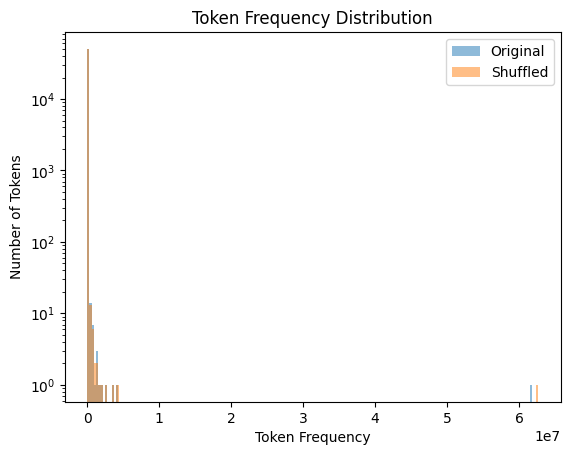

In [18]:
import matplotlib.pyplot as plt

plt.hist(
    list(token_counter.values()), alpha=0.5, label="Original", bins=200
)
plt.hist(
    list(shuffled_token_counter.values()), alpha=0.5, label="Shuffled", bins=200
)
plt.yscale("log")
plt.xlabel("Token Frequency")
plt.ylabel("Number of Tokens")
plt.legend()
plt.title("Token Frequency Distribution")
plt.show()